<a href="https://colab.research.google.com/github/MariaVrett/KNN/blob/main/%CE%9A_%CE%9D%CE%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load Dataset

In [10]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df = df.dropna()
# Droping the ID column because it doesn't give any information
if 'ID' in df.columns:
    df = df.drop('ID', axis=1)
df.head()

,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,Male,48,First-time,Business,Business,821,2,5.0,3,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,Female,35,Returning,Business,Business,821,26,39.0,2,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,Male,41,Returning,Business,Business,853,0,0.0,4,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,Male,50,Returning,Business,Business,1905,0,0.0,2,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,Female,49,Returning,Business,Business,3470,0,1.0,3,3,...,3,4,4,5,4,3,3,3,3,Satisfied


# Histograms and Bar Charts

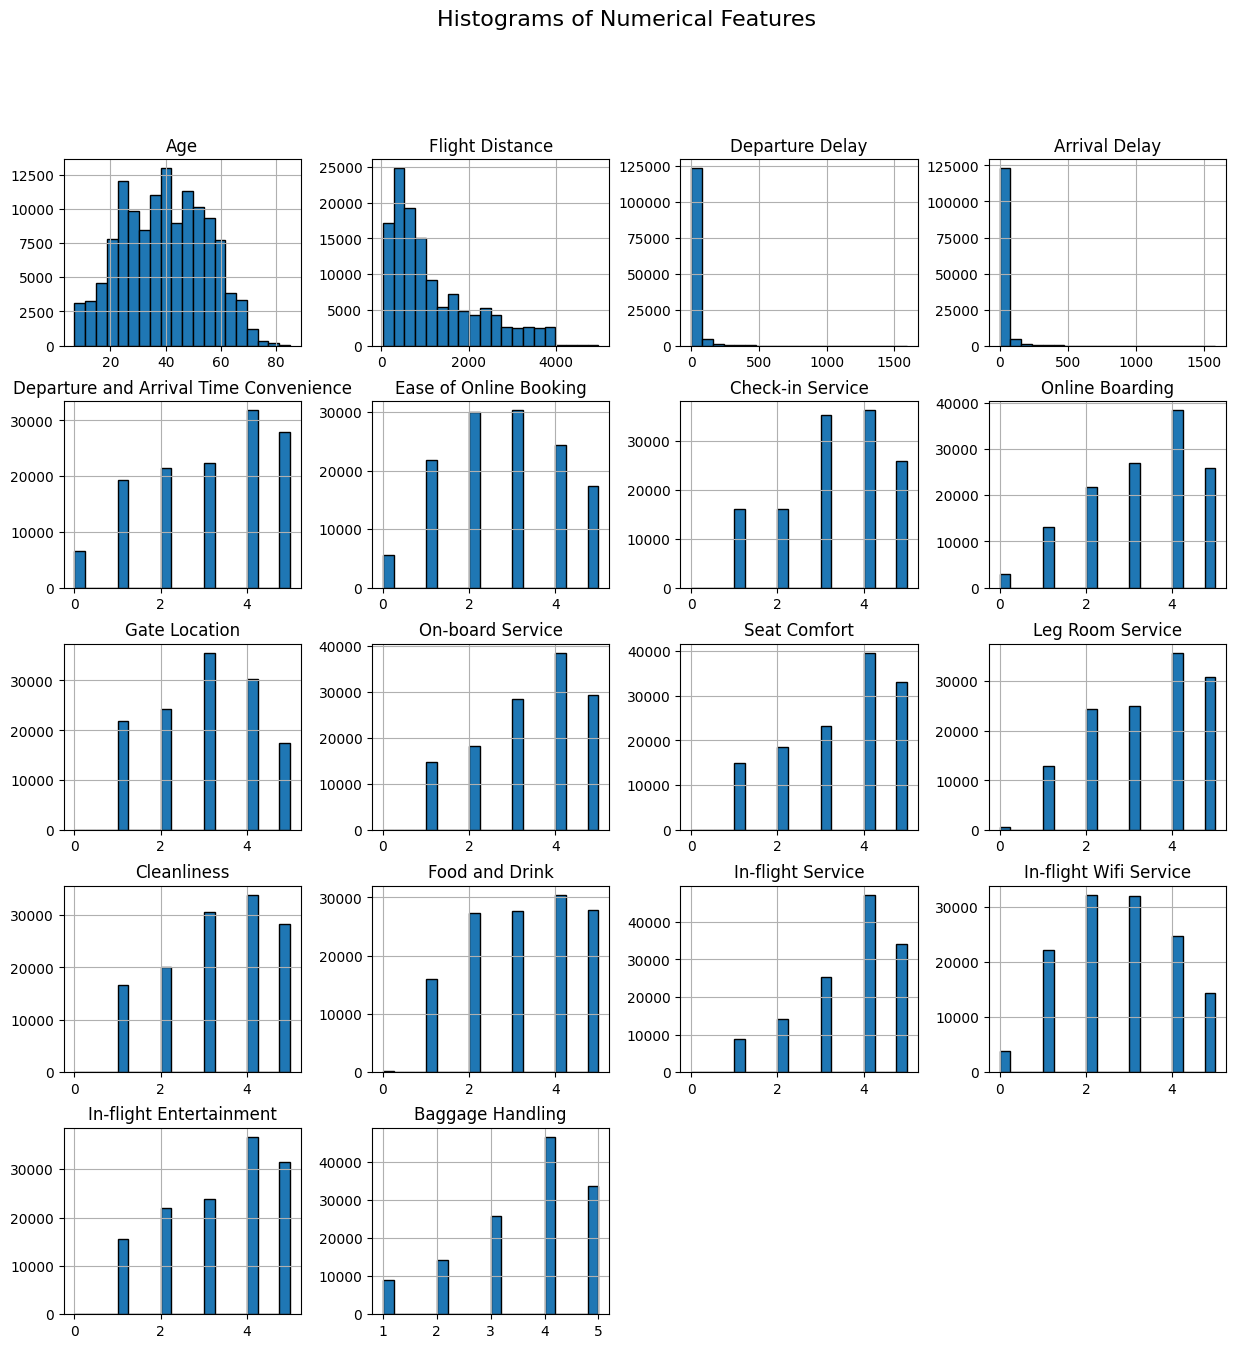

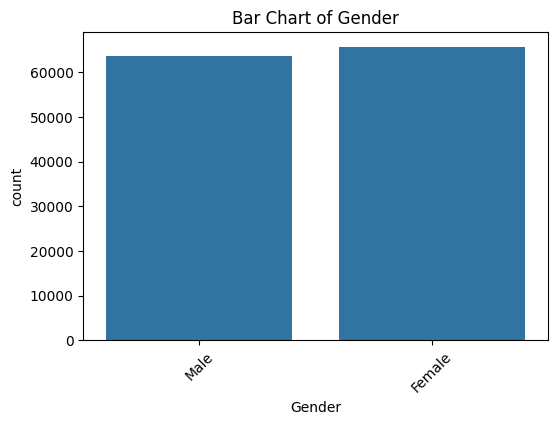

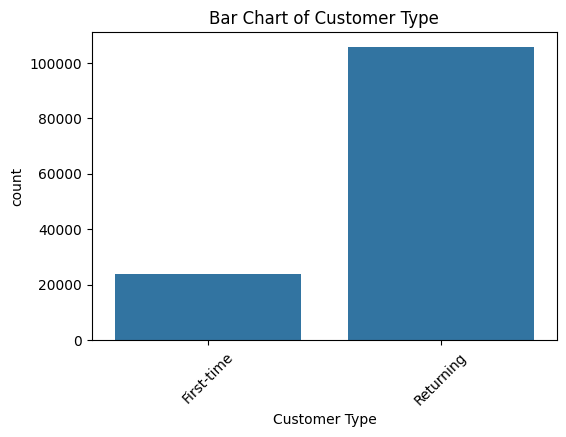

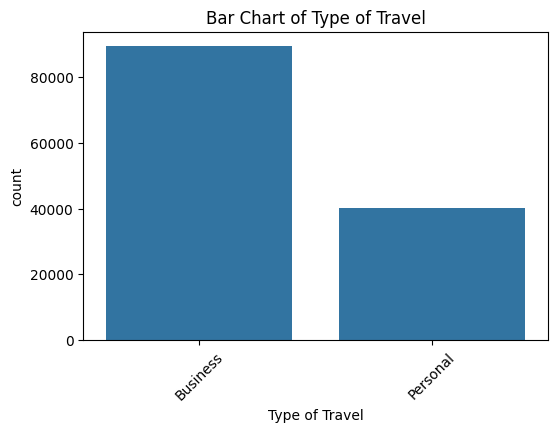

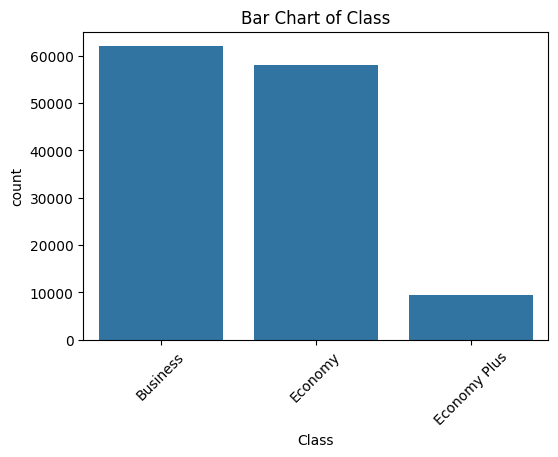

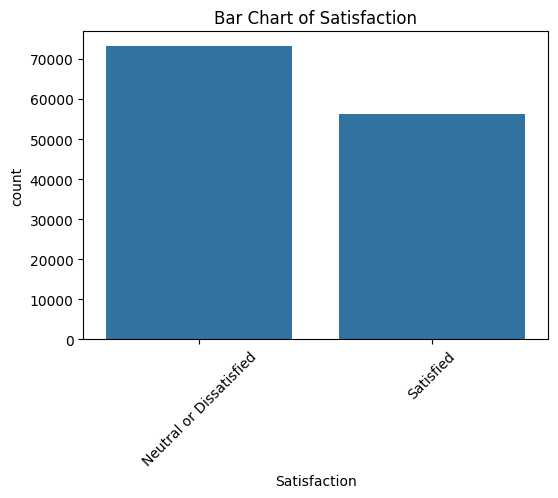

In [11]:
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols].hist(bins=20, figsize=(15, 15), edgecolor='black')
plt.suptitle('Histograms of Numerical Features', fontsize=16)
plt.show()

for col in cat_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Bar Chart of {col}')
    plt.xticks(rotation=45)
    plt.show()

# Class Imbalance Check

In [12]:
class_counts = df['Satisfaction'].value_counts()
class_percentages = df['Satisfaction'].value_counts(normalize=True) * 100

print("Sample Count per class")
print(class_counts)
print("\nPercentages per class:")
print(class_percentages)

if abs(class_percentages.iloc[0] - class_percentages.iloc[1]) > 10:
    print("\nConclusion: There is a class imbalance as one class significantly outweighs the other.")
else:
    print("\nConclusion: The classes are relatively balanced.")

Sample Count per class
Satisfaction
Neutral or Dissatisfied    73225
Satisfied                  56262
Name: count, dtype: int64

Percentages per class:
Satisfaction
Neutral or Dissatisfied    56.550078
Satisfied                  43.449922
Name: proportion, dtype: float64

Conclusion: There is a class imbalance as one class significantly outweighs the other.


# Categorical Encoding

In [13]:
le = LabelEncoder()
df['Satisfaction'] = le.fit_transform(df['Satisfaction'])

cat_cols_features = cat_cols.drop('Satisfaction')
df_encoded = pd.get_dummies(df, columns=cat_cols_features, drop_first=True)

df_encoded.head()

,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,...,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction,Gender_Male,Customer Type_Returning,Type of Travel_Personal,Class_Economy,Class_Economy Plus
0,48,821,2,5.0,3,3,4,3,3,3,...,5,3,5,5,0,True,False,False,False,False
1,35,821,26,39.0,2,2,3,5,2,5,...,5,2,5,5,1,False,True,False,False,False
2,41,853,0,0.0,4,4,4,5,4,3,...,3,4,3,3,1,True,True,False,False,False
3,50,1905,0,0.0,2,2,3,4,2,5,...,5,2,5,5,1,True,True,False,False,False
4,49,3470,0,1.0,3,3,3,5,3,3,...,3,3,3,3,1,False,True,False,False,False


# Convert DataFrame to Numpy arrays and Split Dataset

In [14]:
input_df = df_encoded.drop(columns=['Satisfaction'])
targets_df = df_encoded['Satisfaction']

x = input_df.to_numpy()
y = targets_df.to_numpy()

seed = 0
test_size = 0.30

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
print("Train set shape:", x_train.shape, y_train.shape)
print("Test set shape:", x_test.shape, y_test.shape)



Train set shape: (90640, 23) (90640,)
Test set shape: (38847, 23) (38847,)


# Data Normalization

In [15]:
num_indices = [input_df.columns.get_loc(col) for col in num_cols if col in input_df.columns]

scaler = StandardScaler()
x_train_scaled = np.copy(x_train)
x_test_scaled = np.copy(x_test)

x_train_scaled[:, num_indices] = scaler.fit_transform(x_train[:, num_indices])
x_test_scaled[:, num_indices] = scaler.transform(x_test[:, num_indices])


The KNN algorithm calculates distances between examples to find the nearest neighbors. If a variable has a very large range of values (e.g., `Flight Distance` in thousands of miles) compared to others (e.g., `In-flight Service` from 1 to 5), the variable with the larger values will dominate the distance calculation, distorting the prediction. Normalization ensures that all numerical variables contribute equally by bringing them to the same scale.



# KNN Classifier Training & Evaluation

In [16]:
N = x_train_scaled.shape[0]
k_sqrt_N = int(np.sqrt(N))

k_values = [3, 5, 15, 51, 151, k_sqrt_N]
weights_options = ['uniform', 'distance']
results = []

for k in k_values:
    for w in weights_options:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean')
        knn.fit(x_train_scaled, y_train)

        y_train_pred = knn.predict(x_train_scaled)
        y_test_pred = knn.predict(x_test_scaled)

        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)

        results.append({
            'k': k,
            'Weights': w,
            'Train Accuracy (%)': round(train_acc * 100, 2),
            'Test Accuracy (%)': round(test_acc * 100, 2)
        })

results_df = pd.DataFrame(results)
print("\nAccuracy Results Table:")
display(results_df)

best_idx = results_df['Test Accuracy (%)'].idxmax()
best_k = results_df.loc[best_idx, 'k']
best_w = results_df.loc[best_idx, 'Weights']
best_acc = results_df.loc[best_idx, 'Test Accuracy (%)']

print(f"\nThe best combination is with k={int(best_k)} and weights='{best_w}', achieving a Test Accuracy of {best_acc}%")


Accuracy Results Table:


,k,Weights,Train Accuracy (%),Test Accuracy (%)
0,3,uniform,95.79,92.53
1,3,distance,100.00,92.51
2,5,uniform,94.85,92.75
3,5,distance,100.00,92.74
4,15,uniform,93.43,92.69
5,15,distance,100.00,92.69
6,51,uniform,92.32,92.08
7,51,distance,100.00,92.17
8,151,uniform,91.18,91.02
9,151,distance,100.00,91.12



The best combination is with k=5 and weights='uniform', achieving a Test Accuracy of 92.75%
